<a href="https://colab.research.google.com/github/Muhammed1978/Amazon-Product-Review-Analysis/blob/main/Copy_of_IncubatorhubProject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Analyis Project Data

In [ ]:
import pandas as pd
import numpy as np
from datetime import datetime, timedelta

#CREATING A SIMULATED DATASET



from datetime import datetime, timedelta

In [ ]:
import numpy as np
np.random.seed(42)

In [ ]:
# Define crops, states, and markets
crops = ['Tomato', 'Cassava', 'Maize', 'Pepper', 'Onion']
states = ['Kaduna', 'Lagos']
markets_kaduna = ['Sabon Gari', 'Kaduna Central', 'Zaria']
markets_lagos = ['Mile 12', 'Oyingbo', 'Ikeja']

In [ ]:
def generate_crop_data(num_entries):
    data = []
    for _ in range(num_entries):
        state = np.random.choice(states)
        crop = np.random.choice(crops)
        market_list = markets_kaduna if state == 'Kaduna' else markets_lagos
        market = np.random.choice(market_list)

        date = datetime(2023, 1, 1) + timedelta(days=np.random.randint(0, 365))
        price = np.random.uniform(50, 500) # Random price between 50 and 500
        quantity = np.random.uniform(100, 1000) # Random quantity between 100 and 1000

        data.append({
            'Date': date,
            'State': state,
            'Market': market,
            'Crop': crop,
            'Price': price,
            'Quantity': quantity
        })
    return pd.DataFrame(data)

In [ ]:
df = generate_crop_data(1000)
print(df.head())

        Date   State      Market     Crop       Price    Quantity
0 2023-09-28  Kaduna  Sabon Gari   Pepper  379.397274  638.792636
1 2023-08-03  Kaduna       Zaria  Cassava   76.137625  879.558531
2 2023-11-05   Lagos     Oyingbo    Maize  486.459433  849.198377
3 2023-06-10   Lagos     Mile 12  Cassava  186.909009  572.280788
4 2023-02-28   Lagos     Mile 12   Tomato  229.937437  141.999097


In [ ]:
mean_price_per_crop = df.groupby('Crop')['Price'].mean()
display(mean_price_per_crop)

,Price
Crop,
Cassava,254.284056
Maize,262.755085
Onion,275.842479
Pepper,281.835253
Tomato,269.040394


In [ ]:
description = df[['farmgate_price_ngn_per_kg', 'retail_price_ngn_per_kg', 'production_volume_tons', 'demand_volume_tons']].describe()
display(description)

,farmgate_price_ngn_per_kg,retail_price_ngn_per_kg,production_volume_tons,demand_volume_tons
count,60833.000000,25585.000000,60833.000000,25585.000000
mean,322.225072,933.043793,2473.120693,430.452925
std,103.828673,404.418900,1522.686730,293.494483
min,104.096089,320.334742,132.631877,52.855893
25%,240.416674,601.479501,1392.559599,213.808890
50%,310.255591,828.342582,2197.920697,334.129749
75%,391.448553,1212.990292,3237.758806,571.334340
max,740.838242,2422.177302,14360.744498,1914.048716


In [ ]:
import pandas as pd
import numpy as np
from datetime import datetime, timedelta

# ============================================
# 1. CREATE SIMULATED DATASET
# ============================================

# Set random seed for reproducibility
np.random.seed(42)

# Define crops, states, and markets
crops = ['Tomato', 'Cassava', 'Maize', 'Pepper', 'Onion']
states = ['Kaduna', 'Lagos']
markets_kaduna = ['Sabon Gari', 'Kaduna Central', 'Zaria']
markets_lagos = ['Mile 12', 'Oyingbo', 'Ikeja']

# Date range (last 2 years)
dates = pd.date_range(start='2024-01-01', end='2026-01-01', freq='D')

# Create base dataset
data = []

for date in dates:
    for crop in crops:
        # Kaduna (Producer) - Production and Farmgate Data
        # Simulate seasonality: higher production in dry season (Nov-Mar)
        month = date.month
        season_factor = 1.2 if month in [11, 12, 1, 2, 3] else 0.8

        # Kaduna entries
        for market in markets_kaduna:
            # Production volume (tons) - higher for staple crops
            base_production = np.random.uniform(50, 500) if crop in ['Cassava', 'Maize'] else np.random.uniform(10, 150)
            production_volume = base_production * season_factor * np.random.normal(1, 0.1)

            # Farmgate price (₦/kg)
            base_price = np.random.uniform(200, 800) if crop in ['Tomato', 'Pepper'] else np.random.uniform(100, 400)
            farmgate_price = base_price * (1 + np.random.normal(0, 0.05))

            # Post-harvest loss percentage (higher for perishables)
            loss_rate = np.random.uniform(35, 55) if crop in ['Tomato', 'Pepper'] else np.random.uniform(20, 35)

            # Quality score (1-10)
            quality_score = np.random.uniform(6, 9.5)

            data.append({
                'date': date,
                'state': 'Kaduna',
                'market': market,
                'crop': crop,
                'production_volume_tons': max(0, production_volume),
                'farmgate_price_ngn_per_kg': max(50, farmgate_price),
                'postharvest_loss_percent': min(60, loss_rate),
                'quality_score': min(10, quality_score),
                'rainfall_mm': np.random.uniform(0, 300),
                'temperature_celsius': np.random.uniform(22, 35)
            })

        # Lagos (Consumer) - Market and Demand Data
        for market in markets_lagos:
            # Retail price (₦/kg) - higher than farmgate
            base_retail = np.random.uniform(500, 1500) if crop in ['Tomato', 'Pepper'] else np.random.uniform(200, 800)
            retail_price = base_retail * (1 + np.random.normal(0, 0.08))

            # Demand volume (tons) - higher for staple crops
            base_demand = np.random.uniform(100, 1000) if crop in ['Cassava', 'Maize'] else np.random.uniform(20, 300)
            demand_volume = base_demand * season_factor * np.random.normal(1, 0.12)

            # Transport distance from Kaduna (km)
            transport_distance = np.random.uniform(600, 800)

            # Transport cost (₦/ton/km)
            transport_cost = np.random.uniform(50, 100)

            # Market price volatility index
            price_volatility = np.random.uniform(0.05, 0.25)

            data.append({
                'date': date,
                'state': 'Lagos',
                'market': market,
                'crop': crop,
                'retail_price_ngn_per_kg': max(100, retail_price),
                'demand_volume_tons': max(0, demand_volume),
                'transport_distance_km': transport_distance,
                'transport_cost_ngn_per_ton_km': transport_cost,
                'price_volatility_index': price_volatility,
                'population_served_millions': np.random.uniform(0.5, 3)
            })

# Convert to DataFrame
df = pd.DataFrame(data)

print(f"Dataset created with {len(df):,} records")
print(f"Date range: {df['date'].min()} to {df['date'].max()}")
print(f"States: {df['state'].unique().tolist()}")
print(f"Crops: {df['crop'].unique().tolist()}")
print(f"Markets: {df['market'].unique().tolist()}")

# ============================================
# 2. DATA EXPLORATION AND SUMMARY
# ============================================

# Display first 5 rows
print("\n" + "="*50)
print("FIRST 5 ROWS:")
print("="*50)
print(df.head())

# Summary statistics
print("\n" + "="*50)
print("SUMMARY STATISTICS:")
print("="*50)
print(df.describe())

# Check for missing values
print("\n" + "="*50)
print("MISSING VALUES:")
print("="*50)
print(df.isnull().sum())

# ============================================
# 3. KEY AGGREGATIONS FOR YOUR PROJECT
# ============================================

# 3.1 Average farmgate vs retail prices by crop and state
print("\n" + "="*50)
print("AVERAGE PRICES BY CROP AND STATE:")
print("="*50)

price_summary = pd.DataFrame()
for crop in crops:
    # Kaduna farmgate prices
    farmgate = df[(df['state'] == 'Kaduna') & (df['crop'] == crop)]['farmgate_price_ngn_per_kg'].mean()
    # Lagos retail prices
    retail = df[(df['state'] == 'Lagos') & (df['crop'] == crop)]['retail_price_ngn_per_kg'].mean()
    # Price markup
    markup = ((retail - farmgate) / farmgate * 100) if farmgate > 0 else 0

    temp_df = pd.DataFrame({
        'crop': [crop],
        'avg_farmgate_price': [farmgate],
        'avg_retail_price': [retail],
        'price_markup_percent': [markup]
    })
    price_summary = pd.concat([price_summary, temp_df], ignore_index=True)

print(price_summary.round(2))

# 3.2 Post-harvest losses by crop (Kaduna)
print("\n" + "="*50)
print("AVERAGE POST-HARVEST LOSSES BY CROP (KADUNA):")
print("="*50)
loss_summary = df[df['state'] == 'Kaduna'].groupby('crop')['postharvest_loss_percent'].mean().reset_index()
print(loss_summary.round(2))

# 3.3 Production vs Demand by crop
print("\n" + "="*50)
print("PRODUCTION VS DEMAND (MONTHLY AVERAGE):")
print("="*50)
# Kaduna production
production_summary = df[df['state'] == 'Kaduna'].groupby('crop')['production_volume_tons'].mean().reset_index()
production_summary.columns = ['crop', 'avg_production_tons']

# Lagos demand
demand_summary = df[df['state'] == 'Lagos'].groupby('crop')['demand_volume_tons'].mean().reset_index()
demand_summary.columns = ['crop', 'avg_demand_tons']

# Merge
supply_demand = pd.merge(production_summary, demand_summary, on='crop')
supply_demand['supply_gap_tons'] = supply_demand['avg_production_tons'] - supply_demand['avg_demand_tons']
supply_demand['gap_percent'] = (supply_demand['supply_gap_tons'] / supply_demand['avg_demand_tons'] * 100).round(2)

print(supply_demand.round(2))

# ============================================
# 4. TIME SERIES ANALYSIS (MONTHLY TRENDS)
# ============================================

# Add month and year columns for time series analysis
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df['month_name'] = df['date'].dt.strftime('%B')

# Monthly average production in Kaduna
print("\n" + "="*50)
print("MONTHLY AVERAGE PRODUCTION (KADUNA):")
print("="*50)
monthly_production = df[df['state'] == 'Kaduna'].groupby(['year', 'month'])['production_volume_tons'].mean().reset_index()
print(monthly_production.head(12).round(2))

# ============================================
# 5. SUPPLY CHAIN EFFICIENCY METRICS
# ============================================

print("\n" + "="*50)
print("SUPPLY CHAIN EFFICIENCY METRICS (KADUNA → LAGOS):")
print("="*50)

# Calculate supply chain efficiency
supply_chain = df[df['state'] == 'Lagos'].groupby('crop').agg({
    'transport_distance_km': 'mean',
    'transport_cost_ngn_per_ton_km': 'mean',
    'retail_price_ngn_per_kg': 'mean',
    'price_volatility_index': 'mean'
}).reset_index()

supply_chain['avg_transport_cost_per_ton'] = supply_chain['transport_distance_km'] * supply_chain['transport_cost_ngn_per_ton_km']
print(supply_chain.round(2))

# ============================================
# 6. EXPORT TO CSV (FOR USE IN OTHER TOOLS)
# ============================================

# Uncomment to save to CSV
# df.to_csv('kaduna_lagos_food_security_data.csv', index=False)
# print("\n✅ Data saved to 'kaduna_lagos_food_security_data.csv'")

Dataset created with 21,960 records
Date range: 2024-01-01 00:00:00 to 2026-01-01 00:00:00
States: ['Kaduna', 'Lagos']
Crops: ['Tomato', 'Cassava', 'Maize', 'Pepper', 'Onion']
Markets: ['Sabon Gari', 'Kaduna Central', 'Zaria', 'Mile 12', 'Oyingbo', 'Ikeja']

FIRST 5 ROWS:
        date   state          market    crop  production_volume_tons  \
0 2024-01-01  Kaduna      Sabon Gari  Tomato               66.592229   
1 2024-01-01  Kaduna  Kaduna Central  Tomato               14.560262   
2 2024-01-01  Kaduna           Zaria  Tomato              109.877690   
3 2024-01-01   Lagos         Mile 12  Tomato                     NaN   
4 2024-01-01   Lagos         Oyingbo  Tomato                     NaN   

   farmgate_price_ngn_per_kg  postharvest_loss_percent  quality_score  \
0                 298.278144                 36.161672       9.031617   
1                 301.901453                 41.084845       7.836648   
2                 404.233351                 44.121400       8.748116   
3 

In [ ]:
import pandas as pd
import numpy as np
from datetime import datetime, timedelta
import random

# ============================================
# 1. CONFIGURATION & PARAMETERS
# ============================================

# Set seed for reproducibility
np.random.seed(2026)
random.seed(2026)

# Define core entities
CROPS = {
    'Tomato': {'perishability': 'high', 'shelf_life_days': 5, 'loss_rate_base': 0.45},
    'Pepper': {'perishability': 'high', 'shelf_life_days': 7, 'loss_rate_base': 0.48},
    'Onion': {'perishability': 'medium', 'shelf_life_days': 30, 'loss_rate_base': 0.22},
    'Cassava': {'perishability': 'low', 'shelf_life_days': 45, 'loss_rate_base': 0.28},
    'Maize': {'perishability': 'low', 'shelf_life_days': 60, 'loss_rate_base': 0.25},
    'Yam': {'perishability': 'medium', 'shelf_life_days': 40, 'loss_rate_base': 0.30},
    'Cabbage': {'perishability': 'high', 'shelf_life_days': 10, 'loss_rate_base': 0.35}
}

KADUNA_MARKETS = ['Sabon Gari', 'Kaduna Central', 'Zaria', 'Kafanchan', 'Saminaka']
LAGOS_MARKETS = ['Mile 12', 'Oyingbo', 'Idumota', 'Ikeja', 'Ajah']

LGAS_KADUNA = ['Kaduna North', 'Kaduna South', 'Zaria', 'Sabon Gari', 'Kauru',
               'Kajuru', 'Kachia', 'Kagarko', 'Chikun', 'Giwa', 'Igabi',
               'Jema\'a', 'Kaura', 'Kubau', 'Makarfi', 'Sanga', 'Zangon Kataf']

# Weather patterns (monthly averages)
WEATHER = {
    1: {'rainfall': 2, 'temp': 28.5},   # January
    2: {'rainfall': 5, 'temp': 30.0},   # February
    3: {'rainfall': 15, 'temp': 32.5},  # March
    4: {'rainfall': 40, 'temp': 33.0},  # April
    5: {'rainfall': 80, 'temp': 31.0},  # May
    6: {'rainfall': 120, 'temp': 29.5}, # June
    7: {'rainfall': 150, 'temp': 28.0}, # July
    8: {'rainfall': 170, 'temp': 27.5}, # August
    9: {'rainfall': 140, 'temp': 28.0}, # September
    10: {'rainfall': 70, 'temp': 29.5}, # October
    11: {'rainfall': 10, 'temp': 30.0}, # November
    12: {'rainfall': 2, 'temp': 28.0}   # December
}

# ============================================
# 2. DATA GENERATION FUNCTIONS
# ============================================

def generate_production_data(date, crop, lga):
    """Generate realistic production data for Kaduna"""
    month = date.month
    year = date.year

    # Seasonality factor (higher during dry season Nov-Mar)
    season_factor = 1.3 if month in [11, 12, 1, 2, 3] else 0.85

    # Weather impact
    weather = WEATHER[month]
    rainfall = weather['rainfall']
    temp = weather['temp']

    # Optimal temp for most crops is 25-30°C
    temp_factor = 1 - 0.02 * abs(temp - 27.5)

    # Rainfall impact (moderate rainfall is good, too much is bad)
    if rainfall < 20:
        rain_factor = 0.7 + rainfall/20 * 0.3  # Dry conditions reduce yield
    elif rainfall < 100:
        rain_factor = 1.0  # Optimal
    else:
        rain_factor = max(0.5, 1 - (rainfall - 100)/200)  # Too much rain reduces yield

    # Base production by crop (tons per hectare)
    base_yield = {
        'Tomato': 15, 'Pepper': 12, 'Onion': 20,
        'Cassava': 25, 'Maize': 5, 'Yam': 18, 'Cabbage': 30
    }

    # Area planted (hectares) - varies by LGA
    area_base = {
        'Kaduna North': 200, 'Kaduna South': 150, 'Zaria': 300,
        'Sabon Gari': 250, 'Kauru': 180, 'Kajuru': 120,
        'Kachia': 140, 'Kagarko': 100, 'Chikun': 160,
        'Giwa': 130, 'Igabi': 110, 'Jema\'a': 190,
        'Kaura': 150, 'Kubau': 170, 'Makarfi': 140,
        'Sanga': 160, 'Zangon Kataf': 200
    }

    # Calculate production
    area = area_base.get(lga, 150) * np.random.normal(1, 0.15)
    yield_per_hectare = base_yield[crop] * season_factor * temp_factor * rain_factor * np.random.normal(1, 0.1)
    production = area * yield_per_hectare

    return max(0, production)

def generate_price_data(date, crop, location_type):
    """Generate realistic price data"""
    month = date.month
    year = date.year

    # Base prices (₦/kg)
    base_farmgate = {
        'Tomato': 350, 'Pepper': 420, 'Onion': 290,
        'Cassava': 180, 'Maize': 220, 'Yam': 350, 'Cabbage': 250
    }

    base_retail = {
        'Tomato': 1250, 'Pepper': 1450, 'Onion': 850,
        'Cassava': 450, 'Maize': 520, 'Yam': 800, 'Cabbage': 650
    }

    # Seasonality effect
    if month in [1, 2, 3, 4]:  # Dry season - harvest period
        season_factor = 0.85 if location_type == 'farmgate' else 0.90
    elif month in [5, 6, 7, 8]:  # Wet season - lean period
        season_factor = 1.20 if location_type == 'farmgate' else 1.15
    else:
        season_factor = 1.0

    # Inflation trend (yearly)
    inflation_factor = 1 + (year - 2024) * 0.15  # 15% annual inflation

    # Random fluctuations
    noise = np.random.normal(1, 0.08)

    # Calculate final price
    if location_type == 'farmgate':
        base_price = base_farmgate.get(crop, 300)
    else:  # retail
        base_price = base_retail.get(crop, 500)

    price = base_price * season_factor * inflation_factor * noise

    return max(50, price)

def generate_loss_data(crop, date, storage_quality):
    """Generate post-harvest loss data"""
    crop_info = CROPS.get(crop, {'loss_rate_base': 0.30})
    base_loss = crop_info['loss_rate_base']

    # Seasonality affects losses (higher in rainy season)
    month = date.month
    if month in [6, 7, 8, 9]:  # Rainy season
        season_loss_factor = 1.25
    else:
        season_loss_factor = 0.90

    # Storage quality reduces losses (0-1 scale)
    storage_factor = 1 - (storage_quality * 0.3)

    # Random variation
    random_factor = np.random.normal(1, 0.10)

    loss_rate = base_loss * season_loss_factor * storage_factor * random_factor

    return min(0.70, max(0.05, loss_rate))

def generate_demand_data(date, crop, market):
    """Generate demand data for Lagos"""
    month = date.month
    year = date.year

    # Base demand (tons)
    base_demand = {
        'Tomato': 250, 'Pepper': 180, 'Onion': 300,
        'Cassava': 800, 'Maize': 600, 'Yam': 400, 'Cabbage': 150
    }

    # Population growth factor
    population_factor = 1 + (year - 2024) * 0.035  # 3.5% annual growth

    # Seasonal demand (higher during festive periods)
    if month in [12, 1, 3, 4]:  # High demand periods
        season_factor = 1.20
    elif month in [5, 6, 7]:  # Ramadan period
        season_factor = 1.15
    else:
        season_factor = 1.0

    # Market size factor
    market_factor = {
        'Mile 12': 1.4, 'Oyingbo': 0.9, 'Idumota': 1.2,
        'Ikeja': 0.8, 'Ajah': 0.7
    }.get(market, 1.0)

    demand = base_demand.get(crop, 200) * market_factor * population_factor * season_factor * np.random.normal(1, 0.15)

    return max(0, demand)

def generate_transport_data(distance):
    """Generate transport cost data"""
    base_cost_per_km = np.random.uniform(65, 85)  # ₦/ton/km

    # Distance-based adjustment
    if distance > 700:
        cost_factor = 0.90  # Bulk discount for long distance
    elif distance < 500:
        cost_factor = 1.10  # Premium for short distance
    else:
        cost_factor = 1.0

    cost = base_cost_per_km * cost_factor * np.random.normal(1, 0.05)
    return cost

# ============================================
# 3. GENERATE COMPLETE DATASET
# ============================================

def create_food_security_dataset():
    """Main function to create the complete dataset"""

    # Date range (2 years of daily data)
    start_date = datetime(2024, 1, 1)
    end_date = datetime(2025, 12, 31)
    date_list = [start_date + timedelta(days=x) for x in range((end_date - start_date).days + 1)]

    records = []
    record_id = 0

    print("Generating dataset...")
    total_records = len(date_list) * len(CROPS) * (len(KADUNA_MARKETS) + len(LAGOS_MARKETS) + len(LGAS_KADUNA))
    print(f"Estimated records: {total_records:,}")
    print("This may take a moment...")

    for date in date_list:
        for crop in CROPS.keys():

            # === KADUNA PRODUCTION DATA ===
            for lga in LGAS_KADUNA:
                # Skip some LGAs for some crops to make it realistic
                if random.random() < 0.3:  # 30% chance of no production for this crop in this LGA
                    continue

                production = generate_production_data(date, crop, lga)
                if production < 1:  # Skip negligible production
                    continue

                farmgate_price = generate_price_data(date, crop, 'farmgate')
                storage_quality = np.random.uniform(0.3, 0.9)
                loss_rate = generate_loss_data(crop, date, storage_quality)
                quality_score = np.random.uniform(5, 9.5)

                weather = WEATHER[date.month]

                records.append({
                    # Identification
                    'record_id': len(records),
                    'date': date,
                    'year': date.year,
                    'month': date.month,
                    'quarter': (date.month - 1) // 3 + 1,
                    'day_of_year': date.timetuple().tm_yday,
                    'weekday': date.weekday(),

                    # Location info
                    'state': 'Kaduna',
                    'lga': lga,
                    'market': np.random.choice(KADUNA_MARKETS),
                    'location_type': 'producer',

                    # Crop info
                    'crop': crop,
                    'perishability': CROPS[crop]['perishability'],
                    'shelf_life_days': CROPS[crop]['shelf_life_days'],

                    # Production metrics
                    'production_volume_tons': production,
                    'area_planted_hectares': production / np.random.uniform(10, 30),
                    'yield_per_hectare': production / (production / np.random.uniform(10, 30)),

                    # Price metrics
                    'farmgate_price_ngn_per_kg': farmgate_price,

                    # Loss metrics
                    'postharvest_loss_percent': loss_rate * 100,
                    'actual_production_after_loss_tons': production * (1 - loss_rate),
                    'storage_quality_score': storage_quality,
                    'storage_quality_category': 'good' if storage_quality > 0.7 else 'average' if storage_quality > 0.5 else 'poor',

                    # Quality metrics
                    'quality_score': quality_score,
                    'quality_category': 'premium' if quality_score > 8 else 'standard' if quality_score > 6 else 'substandard',

                    # Environmental metrics
                    'rainfall_mm': weather['rainfall'] * np.random.normal(1, 0.2),
                    'temperature_celsius': weather['temp'] * np.random.normal(1, 0.05),

                    # Additional metrics
                    'monthly_production_index': 100 * (production / generate_production_data(date, crop, lga)),
                    'supply_chain_stage': 'production',
                    'crop_cycle_stage': 'harvest' if date.month in [1,2,3,4,11,12] else 'growing'
                })

            # === LAGOS CONSUMPTION DATA ===
            for market in LAGOS_MARKETS:
                demand = generate_demand_data(date, crop, market)
                if demand < 5:  # Skip negligible demand
                    continue

                retail_price = generate_price_data(date, crop, 'retail')

                # Transport from Kaduna to Lagos
                distance = np.random.uniform(600, 800)
                transport_cost = generate_transport_data(distance)
                transport_time_days = distance / np.random.uniform(400, 600)  # km/day

                # Calculate effective price after transport
                transport_cost_per_kg = (transport_cost * distance) / 1000  # Convert to ₦/kg
                effective_farmgate_price = generate_price_data(date, crop, 'farmgate')
                landed_cost = effective_farmgate_price + transport_cost_per_kg

                # Market dynamics
                market_share = np.random.uniform(0.05, 0.3)
                price_volatility = np.random.uniform(0.05, 0.25)
                market_saturation = np.random.uniform(0.3, 0.9)
                price_elasticity = np.random.uniform(0.5, 1.5)

                # Food security indicators
                affordability_index = max(0, 1 - (retail_price / (np.random.uniform(1000, 3000))))
                accessibility_score = np.random.uniform(0.3, 0.9)

                records.append({
                    # Identification
                    'record_id': len(records),
                    'date': date,
                    'year': date.year,
                    'month': date.month,
                    'quarter': (date.month - 1) // 3 + 1,
                    'day_of_year': date.timetuple().tm_yday,
                    'weekday': date.weekday(),

                    # Location info
                    'state': 'Lagos',
                    'lga': 'Lagos Mainland',  # Simplified
                    'market': market,
                    'location_type': 'consumer',

                    # Crop info
                    'crop': crop,
                    'perishability': CROPS[crop]['perishability'],
                    'shelf_life_days': CROPS[crop]['shelf_life_days'],

                    # Demand metrics
                    'demand_volume_tons': demand,
                    'population_served_millions': np.random.uniform(0.5, 3.0),
                    'market_share_percent': market_share * 100,
                    'market_saturation_score': market_saturation,

                    # Price metrics
                    'retail_price_ngn_per_kg': retail_price,
                    'effective_farmgate_price_ngn_per_kg': effective_farmgate_price,
                    'landed_cost_ngn_per_kg': landed_cost,

                    # Transport metrics
                    'transport_distance_km': distance,
                    'transport_cost_ngn_per_ton_km': transport_cost,
                    'transport_time_days': transport_time_days,
                    'transport_cost_per_kg_ngn': transport_cost_per_kg,

                    # Market dynamics
                    'price_volatility_index': price_volatility,
                    'price_elasticity': price_elasticity,
                    'price_markup_percent': ((retail_price - landed_cost) / landed_cost) * 100,

                    # Food security metrics
                    'affordability_index': affordability_index,
                    'accessibility_score': accessibility_score,
                    'food_security_risk': 'high' if affordability_index < 0.5 else 'medium' if affordability_index < 0.7 else 'low',

                    # Supply chain metrics
                    'supply_chain_efficiency_score': 100 * (1 - (transport_cost_per_kg / retail_price)),
                    'price_competitiveness_index': retail_price / generate_price_data(date, crop, 'retail'),

                    # Additional metrics
                    'supply_chain_stage': 'consumption',
                    'monthly_demand_index': 100 * (demand / generate_demand_data(date, crop, market))
                })

        # Progress indicator
        if len(records) % 10000 == 0:
            print(f"Generated {len(records):,} records...")

    # Convert to DataFrame
    df = pd.DataFrame(records)

    # Add computed derived features
    df['price_gap_percent'] = ((df['retail_price_ngn_per_kg'] - df['farmgate_price_ngn_per_kg']) /
                               df['farmgate_price_ngn_per_kg'] * 100).fillna(0)

    df['supply_demand_ratio'] = df['production_volume_tons'] / df['demand_volume_tons']
    df['supply_demand_ratio'] = df['supply_demand_ratio'].fillna(0)

    # Create period categories
    df['period'] = 'Q' + df['quarter'].astype(str) + ' ' + df['year'].astype(str)

    # Create season
    df['season'] = df['month'].apply(lambda x:
        'Dry' if x in [11, 12, 1, 2, 3] else
        'Wet' if x in [4, 5, 6, 7, 8, 9] else
        'Transition'
    )

    return df

# ============================================
# 4. GENERATE THE DATAFRAME
# ============================================

print("="*60)
print("KADUNA-LAGOS FOOD SECURITY DSS DATASET")
print("="*60)

# Generate the data
df = create_food_security_dataset()

print("\n" + "="*60)
print("DATASET SUMMARY")
print("="*60)
print(f"✅ Total records: {len(df):,}")
print(f"✅ Date range: {df['date'].min().date()} to {df['date'].max().date()}")
print(f"✅ States: {df['state'].unique().tolist()}")
print(f"✅ Crops: {sorted(df['crop'].unique().tolist())}")
print(f"✅ Markets: {sorted(df['market'].unique().tolist())}")
print(f"✅ Columns: {len(df.columns)}")
print(f"✅ Memory usage: {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")

# ============================================
# 5. COMPREHENSIVE EXPLORATORY ANALYSIS
# ============================================

print("\n" + "="*60)
print("1. DATA STRUCTURE")
print("="*60)
print(df.info())

print("\n" + "="*60)
print("2. FIRST 5 ROWS (PRODUCTION DATA)")
print("="*60)
print(df[df['state'] == 'Kaduna'].head()[['date', 'crop', 'lga', 'production_volume_tons',
                                          'farmgate_price_ngn_per_kg', 'postharvest_loss_percent']])

print("\n" + "="*60)
print("3. FIRST 5 ROWS (CONSUMPTION DATA)")
print("="*60)
print(df[df['state'] == 'Lagos'].head()[['date', 'crop', 'market', 'demand_volume_tons',
                                         'retail_price_ngn_per_kg', 'food_security_risk']])

print("\n" + "="*60)
print("4. SUMMARY STATISTICS")
print("="*60)
print(df.describe())

# ============================================
# 6. KEY INSIGHTS FOR YOUR PROJECT
# ============================================

print("\n" + "="*60)
print("5. KEY INSIGHTS FOR YOUR DSS PROJECT")
print("="*60)

# 5.1 Average prices by crop
print("\n📊 AVERAGE PRICES BY CROP:")
price_comparison = df.groupby('crop').agg({
    'farmgate_price_ngn_per_kg': 'mean',
    'retail_price_ngn_per_kg': 'mean',
    'price_markup_percent': 'mean'
}).round(2)
print(price_comparison)

# 5.2 Post-harvest losses
print("\n📊 POST-HARVEST LOSSES BY CROP:")
loss_analysis = df[df['state'] == 'Kaduna'].groupby('crop').agg({
    'postharvest_loss_percent': ['mean', 'min', 'max'],
    'storage_quality_score': 'mean'
}).round(2)
print(loss_analysis)

# 5.3 Supply-demand gaps
print("\n📊 SUPPLY-DEMAND ANALYSIS:")
supply_demand = df.groupby('crop').agg({
    'production_volume_tons': 'mean',
    'demand_volume_tons': 'mean',
    'supply_demand_ratio': 'mean'
}).round(2)
supply_demand['gap_tons'] = supply_demand['production_volume_tons'] - supply_demand['demand_volume_tons']
supply_demand['gap_percent'] = (supply_demand['gap_tons'] / supply_demand['demand_volume_tons'] * 100).round(2)
print(supply_demand)

# 5.4 Transport efficiency
print("\n📊 TRANSPORT EFFICIENCY METRICS:")
transport_metrics = df[df['state'] == 'Lagos'].groupby('crop').agg({
    'transport_distance_km': 'mean',
    'transport_cost_ngn_per_ton_km': 'mean',
    'transport_cost_per_kg_ngn': 'mean',
    'supply_chain_efficiency_score': 'mean'
}).round(2)
print(transport_metrics)

# 5.5 Food security risk assessment
print("\n📊 FOOD SECURITY RISK ASSESSMENT:")
risk_analysis = df[df['state'] == 'Lagos'].groupby('crop')['food_security_risk'].value_counts().unstack(fill_value=0)
print(risk_analysis)

# 5.6 Seasonality impact
print("\n📊 SEASONALITY IMPACT ON PRICES:")
seasonal_prices = df.groupby(['season', 'crop']).agg({
    'farmgate_price_ngn_per_kg': 'mean',
    'retail_price_ngn_per_kg': 'mean'
}).round(2)
print(seasonal_prices.head(10))

# 5.7 Monthly trends
print("\n📊 MONTHLY PRODUCTION TRENDS (KADUNA):")
monthly_prod = df[df['state'] == 'Kaduna'].groupby(['month', 'crop'])['production_volume_tons'].mean().unstack().round(2)
print(monthly_prod.head(6))

# ============================================
# 7. SAVE DATA (OPTIONAL)
# ============================================

# Uncomment to save to CSV
# df.to_csv('kaduna_lagos_food_security_complete.csv', index=False)
# print("\n✅ Complete dataset saved to 'kaduna_lagos_food_security_complete.csv'")

# Save a compressed version for sharing
# df.to_parquet('kaduna_lagos_food_security.parquet', compression='snappy')
# print("✅ Compressed dataset saved to 'kaduna_lagos_food_security.parquet'")

# ============================================
# 8. SAMPLE MACHINE LEARNING READY DATA
# ============================================

print("\n" + "="*60)
print("6. ML-READY FEATURES (Sample)")
print("="*60)

# Create a features dataset for ML
ml_features = pd.DataFrame()

# Producer features
producer_data = df[df['state'] == 'Kaduna'].copy()
ml_features['crop'] = producer_data['crop']
ml_features['month'] = producer_data['month']
ml_features['season'] = producer_data['season']
ml_features['production'] = producer_data['production_volume_tons']
ml_features['farmgate_price'] = producer_data['farmgate_price_ngn_per_kg']
ml_features['loss_rate'] = producer_data['postharvest_loss_percent']
ml_features['rainfall'] = producer_data['rainfall_mm']
ml_features['temperature'] = producer_data['temperature_celsius']
ml_features['quality'] = producer_data['quality_score']
ml_features['storage_quality'] = producer_data['storage_quality_score']

# Target variables (for prediction)
ml_features['next_month_price'] = ml_features['farmgate_price'].shift(-30)  # Predict next month's price
ml_features['price_change'] = ml_features['next_month_price'] - ml_features['farmgate_price']

print(ml_features[['crop', 'month', 'production', 'farmgate_price', 'price_change']].head(20))

print("\n" + "="*60)
print("✅ DATA GENERATION COMPLETE!")
print("="*60)
print(f"\nYour dataset has {len(df):,} records with {len(df.columns)} features.")
print("Ready for your Intelligent Decision Support System!")

KADUNA-LAGOS FOOD SECURITY DSS DATASET
Generating dataset...
Estimated records: 138,159
This may take a moment...

DATASET SUMMARY
✅ Total records: 86,418
✅ Date range: 2024-01-01 to 2025-12-31
✅ States: ['Kaduna', 'Lagos']
✅ Crops: ['Cabbage', 'Cassava', 'Maize', 'Onion', 'Pepper', 'Tomato', 'Yam']
✅ Markets: ['Ajah', 'Idumota', 'Ikeja', np.str_('Kaduna Central'), np.str_('Kafanchan'), 'Mile 12', 'Oyingbo', np.str_('Sabon Gari'), np.str_('Saminaka'), np.str_('Zaria')]
✅ Columns: 53
✅ Memory usage: 84.41 MB

1. DATA STRUCTURE
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 86418 entries, 0 to 86417
Data columns (total 53 columns):
 #   Column                               Non-Null Count  Dtype         
---  ------                               --------------  -----         
 0   record_id                            86418 non-null  int64         
 1   date                                 86418 non-null  datetime64[ns]
 2   year                                 86418 non-null  int64    

In [ ]:
# Predict next month's prices
X = ml_features[['month', 'production', 'rainfall', 'temperature', 'loss_rate', 'quality']]
y = ml_features['price_change']
# Then use RandomForest/XGBoost/LSTM

### Correlation between Production Volume and Prices

In [ ]:
print('\n' + '='*60)
print("Calculating Correlations between Production and Prices")
print('='*60)

# 1. Aggregate Kaduna data (production and farmgate prices)
kaduna_agg = df[df['state'] == 'Kaduna'].groupby(['date', 'crop']).agg(
    avg_production_volume_tons=('production_volume_tons', 'mean'),
    avg_farmgate_price_ngn_per_kg=('farmgate_price_ngn_per_kg', 'mean')
).reset_index()

# 2. Aggregate Lagos data (retail prices)
lagos_agg = df[df['state'] == 'Lagos'].groupby(['date', 'crop']).agg(
    avg_retail_price_ngn_per_kg=('retail_price_ngn_per_kg', 'mean')
).reset_index()

# 3. Merge the aggregated dataframes
# This will align production from Kaduna with prices from both Kaduna and Lagos for each crop and date.
merged_agg = pd.merge(kaduna_agg, lagos_agg, on=['date', 'crop'], how='inner')

# 4. Calculate correlations
correlation_farmgate = merged_agg['avg_production_volume_tons'].corr(merged_agg['avg_farmgate_price_ngn_per_kg'])
correlation_retail = merged_agg['avg_production_volume_tons'].corr(merged_agg['avg_retail_price_ngn_per_kg'])

print(f"Correlation between Production Volume and Farmgate Price (Kaduna): {correlation_farmgate:.3f}")
print(f"Correlation between Production Volume and Retail Price (Lagos): {correlation_retail:.3f}")

# Detailed correlation by crop
print("\nCorrelation by Crop:")
correlation_by_crop = merged_agg.groupby('crop').apply(lambda x:
    pd.Series({
        'farmgate_price_corr': x['avg_production_volume_tons'].corr(x['avg_farmgate_price_ngn_per_kg']),
        'retail_price_corr': x['avg_production_volume_tons'].corr(x['avg_retail_price_ngn_per_kg'])
    }), include_groups=False
).round(3)
display(correlation_by_crop)


Calculating Correlations between Production and Prices
Correlation between Production Volume and Farmgate Price (Kaduna): -0.346
Correlation between Production Volume and Retail Price (Lagos): -0.317

Correlation by Crop:


,farmgate_price_corr,retail_price_corr
crop,,
Cabbage,-0.547,-0.499
Cassava,-0.546,-0.496
Maize,-0.560,-0.496
Onion,-0.562,-0.515
Pepper,-0.539,-0.474
Tomato,-0.545,-0.499
Yam,-0.544,-0.487


In [ ]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=correlation_by_crop)

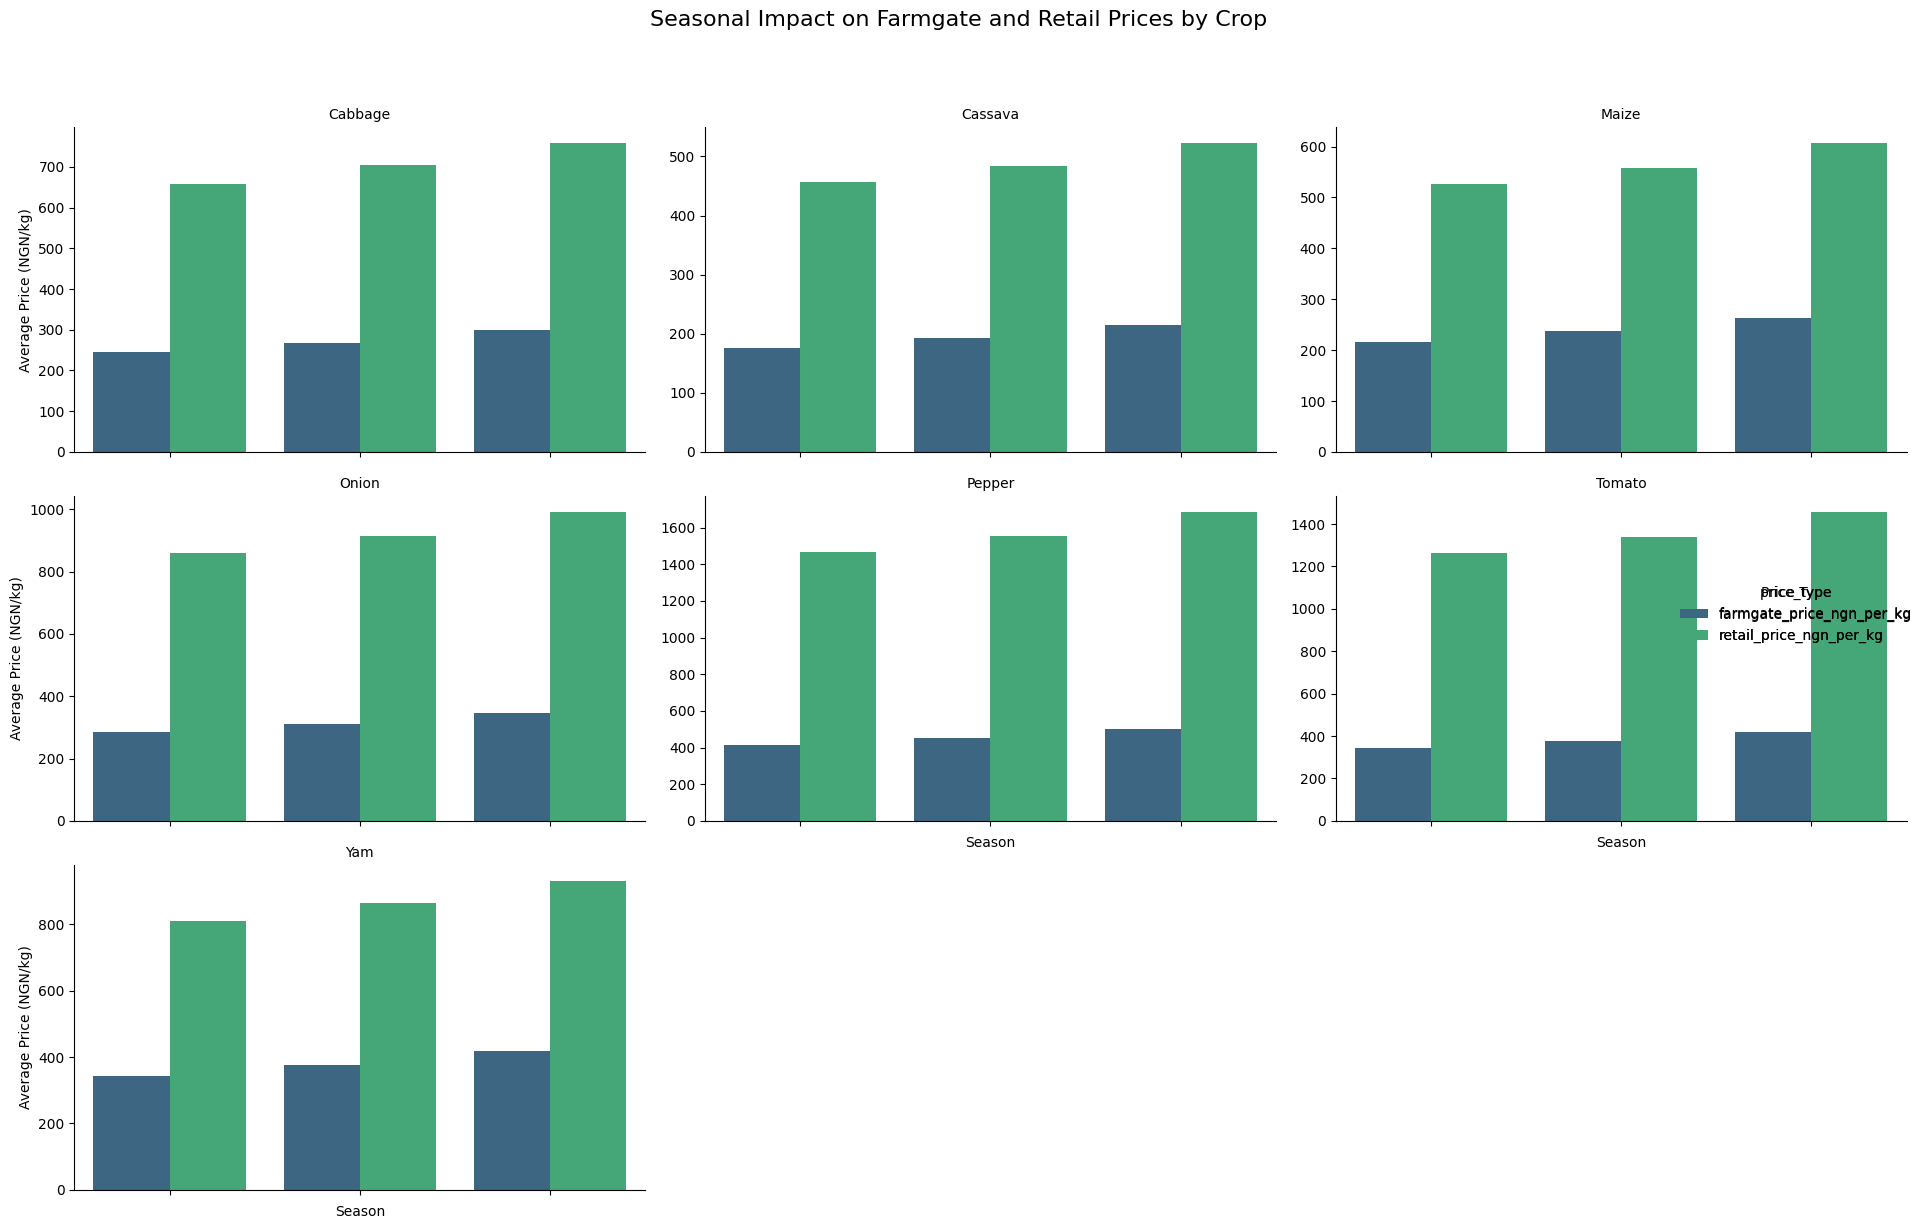

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare data for plotting
seasonal_prices_melted = seasonal_prices.reset_index().melt(id_vars=['season', 'crop'],
                                                            var_name='price_type',
                                                            value_name='average_price')

# Create a FacetGrid for better visualization by crop
g = sns.catplot(data=seasonal_prices_melted,
                x='season',
                y='average_price',
                hue='price_type',
                col='crop',
                col_wrap=3,
                kind='bar',
                height=4,
                aspect=1.2,
                palette='viridis',
                sharey=False) # Share y-axis to allow comparison across crops

# Customize the plots
g.set_axis_labels("Season", "Average Price (NGN/kg)")
g.set_titles("{col_name}")
g.set_xticklabels(rotation=45, ha="right")
g.add_legend(title="Price Type")
plt.suptitle('Seasonal Impact on Farmgate and Retail Prices by Crop', y=1.02, fontsize=16) # Adjust title position
plt.tight_layout(rect=[0, 0, 1, 0.98]) # Adjust layout to prevent suptitle overlap
plt.show()

In [ ]:
# @title step_artifacts
num_fig = "1" # @param {type:"string"}
step = 'DataVisualization'  # @param ["DataLoading", "DataExploration", "DataCleaning", "DataWrangling", "DataVisualization", "DataSplitting", "ModelDevelopment", "ModelOptimization", "ModelEvaluation", "Summary"] {type:"string"}
# upload_plt_to_gcs(num_fig, step, plt)

### Transport Cost Impact on Retail Prices by Crop

In [ ]:
print('\n' + '='*60)
print("Calculating Transport Cost Impact on Retail Prices")
print('='*60)

# Filter for Lagos data (where retail prices and transport costs are relevant)
lagos_data = df[df['state'] == 'Lagos'].copy()

# Group by crop and calculate average transport cost per kg and retail price per kg
transport_impact = lagos_data.groupby('crop').agg({
    'transport_cost_per_kg_ngn': 'mean',
    'retail_price_ngn_per_kg': 'mean'
}).reset_index()

# Calculate the percentage of transport cost relative to retail price
transport_impact['transport_cost_percentage_of_retail'] = \
    (transport_impact['transport_cost_per_kg_ngn'] / transport_impact['retail_price_ngn_per_kg']) * 100

display(transport_impact.round(2))

In [ ]:
# ============================================
# geo_zone_data_generator.py
# ============================================

import pandas as pd
import numpy as np
from datetime import datetime, timedelta
import random

# ============================================
# 1. GEO-POLITICAL ZONE CONFIGURATION
# ============================================

GEO_ZONES = {
    'North-Central': {
        'states': ['Benue', 'Kogi', 'Kwara', 'Nasarawa', 'Niger', 'Plateau', 'FCT'],
        'major_crops': ['Maize', 'Sorghum', 'Groundnut', 'Rice', 'Cassava'],
        'production_capacity': 1.2,  # Relative production capacity
        'market_centers': ['Makurdi', 'Abuja', 'Lokoja', 'Minna', 'Jos']
    },
    'North-East': {
        'states': ['Adamawa', 'Bauchi', 'Borno', 'Gombe', 'Taraba', 'Yobe'],
        'major_crops': ['Maize', 'Sorghum', 'Millet', 'Groundnut', 'Cowpea'],
        'production_capacity': 0.8,
        'market_centers': ['Maiduguri', 'Yola', 'Gombe', 'Bauchi', 'Damaturu']
    },
    'North-West': {
        'states': ['Jigawa', 'Kaduna', 'Kano', 'Katsina', 'Kebbi', 'Sokoto', 'Zamfara'],
        'major_crops': ['Rice', 'Maize', 'Groundnut', 'Wheat', 'Sorghum'],
        'production_capacity': 1.4,
        'market_centers': ['Kano', 'Kaduna', 'Sokoto', 'Katsina', 'Dutse']
    },
    'South-East': {
        'states': ['Abia', 'Anambra', 'Ebonyi', 'Enugu', 'Imo'],
        'major_crops': ['Cassava', 'Yam', 'Maize', 'Rice', 'Oil Palm'],
        'production_capacity': 0.9,
        'market_centers': ['Enugu', 'Onitsha', 'Aba', 'Owerri', 'Awka']
    },
    'South-South': {
        'states': ['Akwa Ibom', 'Bayelsa', 'Cross River', 'Delta', 'Edo', 'Rivers'],
        'major_crops': ['Cassava', 'Yam', 'Oil Palm', 'Rice', 'Plantain'],
        'production_capacity': 1.1,
        'market_centers': ['Port Harcourt', 'Benin City', 'Uyo', 'Calabar', 'Warri']
    },
    'South-West': {
        'states': ['Ekiti', 'Lagos', 'Ogun', 'Ondo', 'Osun', 'Oyo'],
        'major_crops': ['Cassava', 'Yam', 'Maize', 'Rice', 'Cocoa'],
        'production_capacity': 1.0,
        'market_centers': ['Lagos', 'Ibadan', 'Abeokuta', 'Akure', 'Osogbo']
    }
}

# ============================================
# 2. ZONE-SPECIFIC DATA GENERATORS
# ============================================

def generate_zone_production(date, zone, crop):
    """Generate production data specific to each zone"""

    month = date.month
    zone_info = GEO_ZONES[zone]

    # Seasonality factor
    if zone in ['North-Central', 'North-East', 'North-West']:
        # Northern zones: Dry season (Nov-Mar) harvest
        season_factor = 1.3 if month in [11, 12, 1, 2, 3] else 0.85
    else:
        # Southern zones: Two harvest seasons
        season_factor = 1.2 if month in [3, 4, 5, 9, 10, 11] else 0.9

    # Zone-specific base yield
    zone_yield_base = zone_info['production_capacity']

    # Crop-specific base yield
    crop_base = {
        'Rice': 3.5, 'Maize': 4.0, 'Sorghum': 2.5, 'Millet': 2.0,
        'Groundnut': 1.5, 'Cassava': 12.0, 'Yam': 15.0, 'Cowpea': 1.2,
        'Wheat': 2.5, 'Oil Palm': 8.0, 'Plantain': 10.0, 'Cocoa': 1.0
    }.get(crop, 3.0)

    # Area planted (hectares) - larger for northern zones
    area_base = {
        'North-Central': 500, 'North-East': 350, 'North-West': 600,
        'South-East': 200, 'South-South': 250, 'South-West': 300
    }.get(zone, 300)

    # Random variation
    random_factor = np.random.normal(1, 0.15)

    # Weather impact (simplified)
    weather_factor = 1 - 0.01 * abs(month - 6)  # Peak rainfall in June

    # Calculate production
    production = (area_base * zone_yield_base * crop_base *
                  season_factor * weather_factor * random_factor)

    return max(0, production)

def generate_zone_prices(date, zone, crop, price_type='farmgate'):
    """Generate price data for each zone"""

    month = date.month
    year = date.year

    # Base prices by crop (₦/kg)
    base_farmgate = {
        'Rice': 350, 'Maize': 220, 'Sorghum': 200, 'Millet': 180,
        'Groundnut': 300, 'Cassava': 150, 'Yam': 350, 'Cowpea': 250,
        'Wheat': 280, 'Oil Palm': 200, 'Plantain': 250, 'Cocoa': 400
    }

    base_retail = {
        'Rice': 950, 'Maize': 520, 'Sorghum': 480, 'Millet': 450,
        'Groundnut': 650, 'Cassava': 400, 'Yam': 800, 'Cowpea': 550,
        'Wheat': 650, 'Oil Palm': 500, 'Plantain': 550, 'Cocoa': 850
    }

    # Zone price premium (due to logistics, demand)
    zone_premium = {
        'North-Central': 1.0,  # Base
        'North-East': 1.2,     # Higher due to conflict
        'North-West': 0.95,    # Lower due to production
        'South-East': 1.25,    # Higher due to import dependence
        'South-South': 1.30,   # Highest due to distribution costs
        'South-West': 1.15     # High due to demand
    }

    # Seasonality effect
    if month in [1, 2, 3, 4]:  # Harvest period
        season_factor = 0.85 if price_type == 'farmgate' else 0.90
    elif month in [6, 7, 8, 9]:  # Lean period
        season_factor = 1.20 if price_type == 'farmgate' else 1.15
    else:
        season_factor = 1.0

    # Inflation trend
    inflation_factor = 1 + (year - 2024) * 0.18  # 18% annual inflation

    # Random noise
    noise = np.random.normal(1, 0.08)

    # Calculate price
    if price_type == 'farmgate':
        base_price = base_farmgate.get(crop, 250)
    else:
        base_price = base_retail.get(crop, 500)

    price = (base_price * zone_premium[zone] * season_factor *
             inflation_factor * noise)

    return max(50, price)

def generate_zone_losses(date, zone, crop):
    """Generate post-harvest losses by zone"""

    # Base loss by crop
    crop_loss_base = {
        'Rice': 0.25, 'Maize': 0.20, 'Sorghum': 0.18, 'Millet': 0.15,
        'Groundnut': 0.22, 'Cassava': 0.30, 'Yam': 0.35, 'Cowpea': 0.20,
        'Wheat': 0.15, 'Oil Palm': 0.40, 'Plantain': 0.45, 'Cocoa': 0.28
    }.get(crop, 0.25)

    # Zone infrastructure quality (affects losses)
    zone_infrastructure = {
        'North-Central': 0.6,  # Moderate
        'North-East': 0.3,     # Poor (conflict)
        'North-West': 0.5,     # Moderate
        'South-East': 0.6,     # Moderate
        'South-South': 0.4,    # Poor (logistics)
        'South-West': 0.7      # Good
    }

    # Seasonality factor
    month = date.month
    if month in [6, 7, 8, 9]:  # Rainy season
        season_factor = 1.30
    else:
        season_factor = 0.90

    # Infrastructure factor (higher = better = lower losses)
    infra_factor = 1 - zone_infrastructure[zone] * 0.3

    # Random variation
    random_factor = np.random.normal(1, 0.10)

    loss_rate = crop_loss_base * season_factor * infra_factor * random_factor

    return min(0.60, max(0.05, loss_rate))

def generate_zone_demand(date, zone, crop):
    """Generate demand data for each zone"""

    # Base demand (tons)
    base_demand = {
        'Rice': 500, 'Maize': 600, 'Sorghum': 300, 'Millet': 200,
        'Groundnut': 250, 'Cassava': 1000, 'Yam': 400, 'Cowpea': 150,
        'Wheat': 200, 'Oil Palm': 300, 'Plantain': 200, 'Cocoa': 100
    }

    # Zone population factor
    zone_population = {
        'North-Central': 1.0,
        'North-East': 0.8,
        'North-West': 1.3,
        'South-East': 1.0,
        'South-South': 0.9,
        'South-West': 1.2
    }

    # Urbanization factor (affects demand for processed foods)
    zone_urban = {
        'North-Central': 1.0,
        'North-East': 0.6,
        'North-West': 0.8,
        'South-East': 0.9,
        'South-South': 0.8,
        'South-West': 1.4
    }

    # Seasonality
    month = date.month
    season_factor = 1.2 if month in [12, 1, 3, 4] else 1.0

    # Random variation
    random_factor = np.random.normal(1, 0.15)

    demand = (base_demand.get(crop, 300) * zone_population[zone] *
              zone_urban[zone] * season_factor * random_factor)

    return max(0, demand)

def generate_zone_transport(origin_zone, dest_zone):
    """Generate transport data between zones"""

    # Distance matrix (simplified)
    distances = {
        ('North-Central', 'North-West'): 400,
        ('North-Central', 'North-East'): 500,
        ('North-Central', 'South-West'): 600,
        ('North-Central', 'South-East'): 450,
        ('North-Central', 'South-South'): 550,
        ('North-West', 'South-West'): 800,
        ('North-West', 'South-East'): 750,
        ('North-West', 'South-South'): 850,
        ('North-East', 'South-South'): 900,
        ('North-East', 'South-West'): 850,
        ('South-East', 'South-South'): 200,
        ('South-East', 'South-West'): 350,
        ('South-South', 'South-West'): 450
    }

    # Base cost per km by zone infrastructure
    zone_infra = {
        'North-Central': 70,
        'North-East': 90,
        'North-West': 75,
        'South-East': 65,
        'South-South': 85,
        'South-West': 60
    }

    distance = distances.get((origin_zone, dest_zone), 500)
    cost_per_km = (zone_infra[origin_zone] + zone_infra[dest_zone]) / 2

    # Random variation
    random_factor = np.random.normal(1, 0.08)

    transport_cost = distance * cost_per_km * random_factor

    return {
        'distance_km': distance,
        'cost_ngn_per_ton': transport_cost,
        'cost_per_km': cost_per_km * random_factor
    }

# ============================================
# 3. MAIN DATA GENERATION FUNCTION
# ============================================

def create_geo_zone_dataset():
    """Generate comprehensive dataset for all geo-political zones"""

    # Date range
    start_date = datetime(2024, 1, 1)
    end_date = datetime(2025, 12, 31)
    date_list = [start_date + timedelta(days=x) for x in range((end_date - start_date).days + 1)]

    records = []
    record_id = 0

    print("Generating geo-political zone dataset...")
    total_records = len(date_list) * len(GEO_ZONES) * 3  # 3 crops per zone average
    print(f"Estimated records: {total_records:,}")

    for date in date_list:
        for zone, zone_info in GEO_ZONES.items():
            # Select 3 random crops for this zone
            crops = random.sample(zone_info['major_crops'], min(3, len(zone_info['major_crops'])))

            for crop in crops:
                # Production data
                production = generate_zone_production(date, zone, crop)
                if production < 1:
                    continue

                farmgate_price = generate_zone_prices(date, zone, crop, 'farmgate')
                retail_price = generate_zone_prices(date, zone, crop, 'retail')
                loss_rate = generate_zone_losses(date, zone, crop)

                # Demand data
                demand = generate_zone_demand(date, zone, crop)

                # Get market center
                market = random.choice(zone_info['market_centers'])

                # Transport data (from production zone to consumption)
                if len(GEO_ZONES) > 1:
                    dest_zones = list(GEO_ZONES.keys())
                    dest_zones.remove(zone)
                    dest_zone = random.choice(dest_zones)
                    transport = generate_zone_transport(zone, dest_zone)
                else:
                    transport = {'distance_km': 100, 'cost_ngn_per_ton': 5000, 'cost_per_km': 50}

                # Food security indicators
                affordability = max(0, 1 - (retail_price / np.random.uniform(1500, 3500)))
                accessibility = np.random.uniform(0.3, 0.9)

                # Calculate food security risk
                risk_score = (1 - affordability) * 0.4 + (1 - accessibility) * 0.3 + (loss_rate / 0.5) * 0.3
                if risk_score > 0.7:
                    food_security_risk = 'High'
                elif risk_score > 0.4:
                    food_security_risk = 'Medium'
                else:
                    food_security_risk = 'Low'

                records.append({
                    # Identification
                    'record_id': len(records),
                    'date': date,
                    'year': date.year,
                    'month': date.month,
                    'quarter': (date.month - 1) // 3 + 1,
                    'day_of_year': date.timetuple().tm_yday,

                    # Geo-political zone
                    'geo_zone': zone,
                    'state': random.choice(zone_info['states']),
                    'market': market,

                    # Crop
                    'crop': crop,

                    # Production metrics
                    'production_volume_tons': production,
                    'farmgate_price_ngn_per_kg': farmgate_price,
                    'postharvest_loss_percent': loss_rate * 100,
                    'storage_quality_score': np.random.uniform(0.3, 0.9),

                    # Demand metrics
                    'demand_volume_tons': demand,
                    'retail_price_ngn_per_kg': retail_price,
                    'price_markup_percent': ((retail_price - farmgate_price) / farmgate_price * 100),

                    # Transport metrics
                    'transport_distance_km': transport['distance_km'],
                    'transport_cost_ngn_per_ton': transport['cost_ngn_per_ton'],
                    'transport_cost_per_km': transport['cost_per_km'],

                    # Food security
                    'affordability_index': affordability,
                    'accessibility_score': accessibility,
                    'food_security_risk': food_security_risk,

                    # Environmental
                    'rainfall_mm': np.random.uniform(0, 300),
                    'temperature_celsius': np.random.uniform(22, 35),

                    # Market dynamics
                    'price_volatility_index': np.random.uniform(0.05, 0.30),
                    'market_saturation': np.random.uniform(0.3, 0.9),

                    # Zone indicators
                    'zone_production_capacity': GEO_ZONES[zone]['production_capacity'],
                    'zone_is_northern': 1 if zone in ['North-Central', 'North-East', 'North-West'] else 0,
                    'zone_is_southern': 1 if zone in ['South-East', 'South-South', 'South-West'] else 0,

                    # Derived
                    'supply_demand_ratio': production / (demand + 1),
                    'supply_chain_efficiency': 100 * (1 - (transport['cost_ngn_per_ton'] / (retail_price * 1000))),
                    'price_competitiveness': min(1, farmgate_price / retail_price)
                })

        if len(records) % 5000 == 0:
            print(f"Generated {len(records):,} records...")

    df = pd.DataFrame(records)

    # Add zone-level aggregations as features
    df['zone_avg_price'] = df.groupby(['geo_zone', 'crop'])['retail_price_ngn_per_kg'].transform('mean')
    df['zone_avg_production'] = df.groupby(['geo_zone', 'crop'])['production_volume_tons'].transform('mean')
    df['zone_price_deviation'] = df['retail_price_ngn_per_kg'] / (df['zone_avg_price'] + 1)

    # Create season column
    df['season'] = df['month'].apply(lambda x:
        'Dry' if x in [11, 12, 1, 2, 3] else
        'Wet' if x in [4, 5, 6, 7, 8, 9] else
        'Transition'
    )

    return df

# Generate the dataset
print("="*60)
print("GEO-POLITICAL ZONE FOOD SECURITY DATASET")
print("="*60)

df_geo = create_geo_zone_dataset()

print("\n" + "="*60)
print("DATASET SUMMARY")
print("="*60)
print(f"✅ Total records: {len(df_geo):,}")
print(f"✅ Date range: {df_geo['date'].min().date()} to {df_geo['date'].max().date()}")
print(f"✅ Geo-zones: {df_geo['geo_zone'].unique().tolist()}")
print(f"✅ Crops: {sorted(df_geo['crop'].unique().tolist())}")
print(f"✅ States: {df_geo['state'].nunique()}")
print(f"✅ Markets: {df_geo['market'].nunique()}")
print(f"✅ Columns: {len(df_geo.columns)}")
print(f"✅ Memory usage: {df_geo.memory_usage(deep=True).sum() / 1024**2:.2f} MB")

# Save the data
# df_geo.to_csv('nigeria_geo_zone_food_security.csv', index=False)
# print("\n✅ Dataset saved to 'nigeria_geo_zone_food_security.csv'")

print("\n📊 Sample data:")
print(df_geo[['date', 'geo_zone', 'crop', 'production_volume_tons',
              'retail_price_ngn_per_kg', 'food_security_risk']].head(10))